In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import factorial
from scipy.stats import poisson
from scipy.stats import binom
import random
import scipy.special as special

# for reproducibility
rng = np.random.default_rng(seed=42)

# Part c

In [2]:
arrival_rate = 3.0  # lambda = points / minute per team
max_time = 48.0     # game duration (minutes)


def arrival_times(arrival_rate, max_time):
  current_time = 0.0
  arrival_times = []

  # generate events while t in [0, 48]
  while current_time < max_time:
      # Sample the next time increment using expovariate
      inter_arrival = random.expovariate((arrival_rate))
      current_time += inter_arrival

      if current_time <= max_time:
          arrival_times.append(current_time)

  return arrival_times

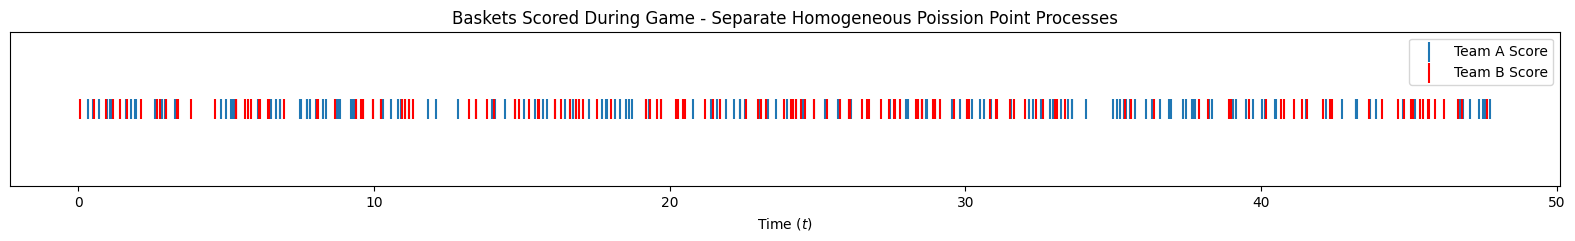

In [3]:
# sample team A and team B points separately
arrival_times_A = arrival_times(arrival_rate, max_time)
y_A = np.zeros_like(arrival_times_A)

arrival_times_B = arrival_times(arrival_rate, max_time)
y_B = np.zeros_like(arrival_times_B)

# plot points scored
plt.figure(figsize=(20, 2))
plt.yticks([])

plt.xlabel(f"Time $(t)$")

plt.scatter(arrival_times_A, y_A, marker = "|", label = 'Team A Score', s = 200)
plt.scatter(arrival_times_B, y_B, c = 'r', marker = "|", label = 'Team B Score', s = 200)
plt.title("Baskets Scored During Game - Separate Homogeneous Poission Point Processes")
plt.legend()
plt.show()

# Part d

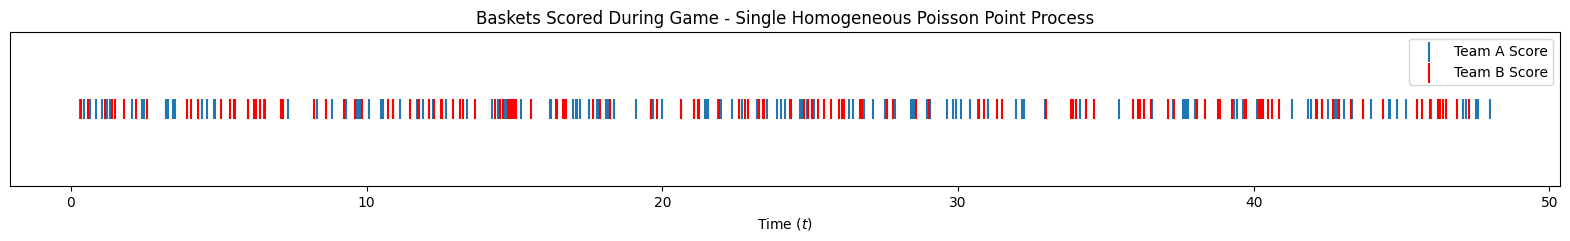

In [4]:
# combined process with rate = lambda + lambda
# and P(Y=A) = P(Y=B) = 0.5
# by HPPP thinning, the combined arrival rate is now cut in half

# the combined rate is 2 * lambda = 6
combined_rate = arrival_rate + arrival_rate

# by thinning, N_A ~ HPPP(combined_rate * 1/2) and
#  N_B ~ HPPP(combined_rate * 1/2)
arrival_times_A = arrival_times(combined_rate / 2, 48)
arrival_times_B = arrival_times(combined_rate / 2, 48)

# plot points scored
plt.figure(figsize=(20, 2))
plt.yticks([])

y_A = np.zeros_like(arrival_times_A)
y_B = np.zeros_like(arrival_times_B)

plt.xlabel(f"Time $(t)$")

plt.scatter(arrival_times_A, y_A, marker = "|", label = 'Team A Score', s = 200)
plt.scatter(arrival_times_B, y_B, c = 'r', marker = "|", label = 'Team B Score', s = 200)
plt.title("Baskets Scored During Game - Single Homogeneous Poisson Point Process")
plt.legend()
plt.show()

# Part e

In [12]:
# simulate 10^5 games
# use N ~ Poisson(2*lambda*t) and
#  N_A | N ~ Binomial(N, 0.5)
# compute E[D(t)], Var[D(t)], and P(D(t)=0) for t=48

lmbda = 3                          # team points / minute
lmbda_c = lmbda * 2                # combined rate
lmbda_thinned = lmbda / lmbda_c    # lambda used for thinned poisson process
t = 48                             # game duration, minutes


print(f'Thinned lambda: 2 * lambda * t = {2 * lmbda_thinned * t}\n\n')

# sample total points scored in game
# N ~ Poisson(2 * lambda_thinned * t)
N = np.random.poisson(lam = 2 * lmbda_thinned * t, size = 100000)

# sample points scored by team A
# N_A ~ Binomial(N, 1/2)
N_A = np.random.binomial(n = N, p = 0.5, size = 100000)

# points scored by team B
N_B = N - N_A

# compute and store difference between teams' total points
score_deltas = [np.abs(x-y) for x,y in zip(N_A, N_B)]

# games where score difference is zero
zero_delta = [x for x in score_deltas if x ==  0]
# compute fraction of scores where differece is zero
p_zero = len(zero_delta)/len(score_deltas)


print(f'Simulated E[D(t)] = {np.mean(score_deltas)}')
print(f'Theoretical E[D(t)] = 0\n\n')

print(f'Simulated VAR[D(t)] = {np.round(np.var(score_deltas),5)}')
print(f'Theoretical VAR[D(t)] = {8 * lmbda}\n\n')

print(f'Simulated P(D(t)=0) = {np.round(p_zero, 5)}')
# special.io(rate) computes modified Bessel function of the first kind
print(f'Theoretical P(D(t)=0) = {np.round(np.exp(-2 * lmbda_thinned * t) * special.i0(2 * lmbda_thinned * t), 5)}')

Thinned lambda: 2 * lambda * t = 48.0


Simulated E[D(t)] = 5.50792
Theoretical E[D(t)] = 0


Simulated VAR[D(t)] = 17.6547
Theoretical VAR[D(t)] = 24


Simulated P(D(t)=0) = 0.05836
Theoretical P(D(t)=0) = 0.05773
